# 03 - Baseline

**Objective:** have a simple reference against which to measure feature engineering and later models.

**Approach:** LightGBM with raw variables (no feature engineering), trained on train and evaluated on validation. The **test** segment is **not touched** until the end of the project, so that the final evaluation is honest.

In [1]:
import sys
sys.path.append("..")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import lightgbm as lgb
from sklearn.metrics import precision_recall_curve

from src.validation import add_day, temporal_split
from src.evaluate import evaluate, evaluate_by_segment

sns.set_theme(style="whitegrid")

## 1. Data and temporal split

In [2]:
df = add_day(pd.read_parquet("../data/processed/train_merged.parquet"))

# LightGBM necesita dtype 'category' para las variables categóricas
cat_cols = [c for c in df.columns if not pd.api.types.is_numeric_dtype(df[c])]
for c in cat_cols:
    df[c] = df[c].astype("category")
print(f"{len(cat_cols)} categorical columns")

train, valid, test = temporal_split(df)
print(len(train), len(valid), len(test))

31 categorical columns
410601 85303 94636


## 2. Variable selection
The following are excluded:
- `TransactionID`: an identifier, it has no predictive meaning.
- `TransactionDT` and `day`: absolute time does not extrapolate to the future (the valid/test segments have values outside the range seen in train).
- `isFraud`: the target.

In [3]:
DROP = ["TransactionID", "TransactionDT", "day", "isFraud"]
features = [c for c in df.columns if c not in DROP]

X_train, y_train = train[features], train["isFraud"]
X_valid, y_valid = valid[features], valid["isFraud"]
len(features)

432

## 3. Model
Reasonable parameters and no tuning. No adjustment for class imbalance yet: this is the starting point. Early stopping on validation.

In [4]:
params = dict(
    objective="binary",
    learning_rate=0.05,
    n_estimators=2000,
    num_leaves=64,
    colsample_bytree=0.5,
    subsample=0.8,
    subsample_freq=1,
    random_state=42,
    n_jobs=-1,
    verbose=-1,
)

model = lgb.LGBMClassifier(**params)
model.fit(
    X_train, y_train,
    eval_set=[(X_valid, y_valid)],
    eval_metric="auc",
    callbacks=[lgb.early_stopping(100), lgb.log_evaluation(100)],
)
print("Best iteration:", model.best_iteration_)

c:\Users\Carlos\AppData\Local\Programs\Python\Python313\Lib\site-packages\lightgbm\sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)


Training until validation scores don't improve for 100 rounds
[100]	valid_0's auc: 0.906486	valid_0's binary_logloss: 0.0898731
[200]	valid_0's auc: 0.91775	valid_0's binary_logloss: 0.0856414
[300]	valid_0's auc: 0.920376	valid_0's binary_logloss: 0.0843805
[400]	valid_0's auc: 0.923574	valid_0's binary_logloss: 0.0833867
[500]	valid_0's auc: 0.92428	valid_0's binary_logloss: 0.0831447
[600]	valid_0's auc: 0.925021	valid_0's binary_logloss: 0.0830404
Early stopping, best iteration is:
[559]	valid_0's auc: 0.925052	valid_0's binary_logloss: 0.082948
Best iteration: 559


## 4. Evaluation on validation

In [5]:
p_valid = model.predict_proba(X_valid)[:, 1]
results = evaluate(y_valid, p_valid)
pd.Series(results).round(4)

auc_pr           0.6113
auc_roc          0.9251
tasa_base        0.0347
recall@prec50    0.6026
recall@prec80    0.4450
dtype: float64

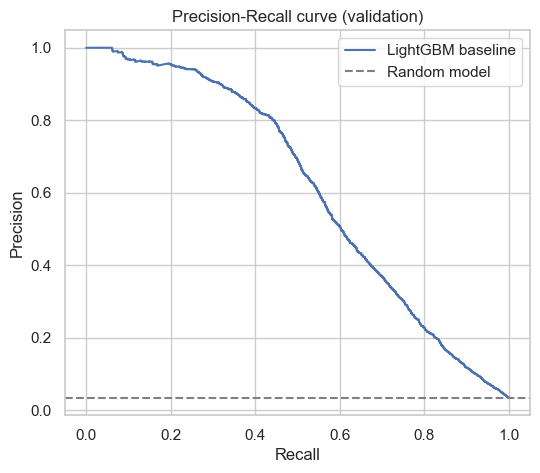

In [6]:
prec, rec, _ = precision_recall_curve(y_valid, p_valid)
plt.figure(figsize=(6, 5))
plt.plot(rec, prec, label="LightGBM baseline")
plt.axhline(y_valid.mean(), color="gray", linestyle="--", label="Random model")
plt.xlabel("Recall"); plt.ylabel("Precision"); plt.title("Precision-Recall curve (validation)")
plt.legend(); plt.show()

## 5. Evaluation by segment
As seen in the temporal validation, `ProductCD` and `has_identity` change in composition across segments. We verify that the model performs similarly in each segment.

In [7]:
evaluate_by_segment(valid, p_valid, "ProductCD")

,rows,frauds,rate_fraud_%,auc_pr,auc_roc
ProductCD,,,,,
C,8874,1123,12.6549,0.8071,0.9320
H,2270,135,5.9471,0.7158,0.9404
R,3245,161,4.9615,0.8660,0.9765
S,1347,86,6.3846,0.6719,0.9127
W,69567,1457,2.0944,0.3872,0.9006


In [8]:
evaluate_by_segment(valid, p_valid, "has_identity")

,rows,frauds,rate_fraud_%,auc_pr,auc_roc
has_identity,,,,,
0,70187,1496,2.1314,0.3915,0.9009
1,15116,1466,9.6983,0.8005,0.9426


## 6. Feature importance

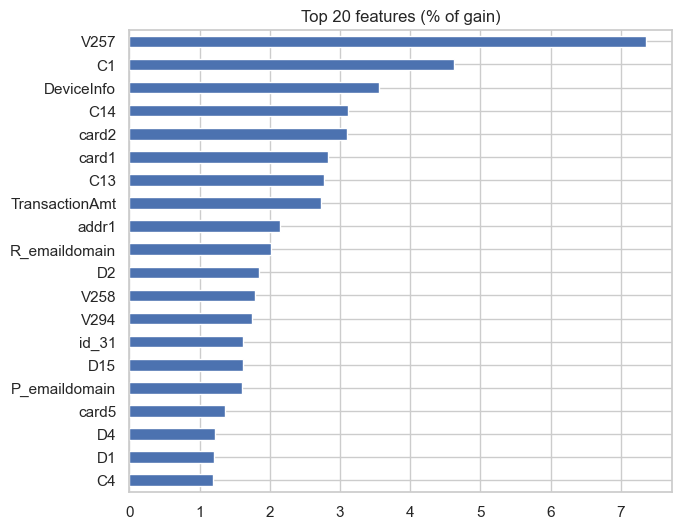

In [9]:
imp = pd.Series(model.booster_.feature_importance(importance_type="gain"), index=features)
imp = (imp / imp.sum() * 100).sort_values(ascending=False)
imp.head(20).iloc[::-1].plot(kind="barh", figsize=(7, 6), title="Top 20 features (% of gain)")
plt.show()

## 7. Baseline conclusions

**Results (temporal validation)**
- PR-AUC: 0.611 (≈17x the base rate of 3.47%) | ROC-AUC: 0.925.
- Recall at precision ≥50%: 60.3% | at precision ≥80%: 44.5%.
- Best iteration: 559 (learning rate 0.05, no imbalance adjustment).

**Performance by segment**
- ROC-AUC is high and stable across all segments (0.90-0.98).
- The lowest PR-AUC in `ProductCD = W` (0.39) and `has_identity = 0` (0.39) reflects their lower fraud rate (~2.1%), not worse relative performance: it equals ~18x the segment's base rate.
- These two segments account for ~82% of transactions and are the hardest; this is where there is the most to gain.

**Most important variables**
- V257 (masked), C1, C13, C14, card1, card2, DeviceInfo.
- Variables that identify or describe the customer/device predominate, which suggests working on an approximate customer identifier and on per-customer aggregations.

**Limitations**
- Early stopping on validation: the metric is slightly optimistic; the test set is reserved for the final result.
- Masked variables (V*): they limit interpretability.

**Next steps**
- Feature engineering focused on the approximate customer, frequencies, and temporal behavior.